# ZeroLoop: Complaint-Text Analytics Pipeline Prototype
### Tested on Public FDA Food Recall Enforcement Data

---

### IMPORTANT HONESTY RULES
> 1. **The data is FDA food RECALLS, not customer complaints.** It is only a test bed for the method and pipeline architecture.
> 2. **Keyword labels are WEAK labels.** Never report accuracy measured against them as real performance, because that is circular.
> 3. **Real accuracy is measured only on a hand-labelled gold set.**

---

### Overview & Objectives
This starter notebook implements an end-to-end prototype for text analytics on incident / complaint data:
1. **Public API Ingestion**: Retrieval from openFDA (2012–2026) including `event_id` and `recall_initiation_date` with local caching.
2. **Data Sanitization & Preprocessing**: Deduplication, dual datetime normalization, date validation with fallback, and chronological ordering.
3. **Weak-Supervision Taxonomy**: Deterministic keyword matching into 7 canonical operational categories.
4. **Pareto Frequency Analysis**: Prioritizing defect drivers with "other" placed last and validated threshold callouts.
5. **Recurrence & Chronic Candidates Tracking**: Event-level tracking using openFDA `event_id`, fuzzy firm alias normalization, and validated event date deltas.
6. **Gold Standard Sampling & Blind Annotation**: Double-blind independent human labeling protocol with unanchored sheets.
7. **Inter-Annotator Agreement (Step 6b)**: Cohen's Kappa evaluation, category disagreement matrix, and consensus adjudication.
8. **Model Training & Honest Evaluation**: Training TF-IDF + Logistic Regression on weak labels with evaluation restricted solely to held-out gold truth.
9. **Next Steps**: Architectural roadmap for sentence embeddings, density clustering, survival analysis, and synthetic simulation.
10. **Sanity Checks**: Automated verification of dataset integrity, temporal boundaries, and recurrence constraints.

All steps run on standard laptop CPUs and Google Colab using standard Python libraries (`pandas`, `scikit-learn`, `matplotlib`, `requests`).


## Step 1: Data Ingestion from openFDA API (2012–2026)
We fetch food enforcement recall records from the openFDA public endpoint:
`https://api.fda.gov/food/enforcement.json`

#### Ingestion Fields & Verification:
- **Year Range**: 2012 through 2026 inclusive.
- **Fields Kept**:
  - `recall_number`
  - `event_id` *(verified directly in API response; groups individual product rows belonging to the same recall action)*
  - `recall_initiation_date` *(verified directly in API response; records when the recall action was first initiated)*
  - `report_date`
  - `recalling_firm`
  - `product_description`
  - `reason_for_recall`
  - `classification`
  - `status`
  - `state`
  - `country`
  - `distribution_pattern`
- **String URL Construction**: Unencoded `+TO+` in `report_date:[YYYY0101+TO+YYYY1231]` to comply with openFDA Lucene syntax.
- **Paging Protocol**: Paged with `limit=1000` and `skip <= 25000`, with `0.3s` sleep between requests.
- **404 Handling**: Handled as an empty result partition.
- **Disk Caching**: Cached to `fda_food_enforcement.csv`.


In [1]:
import os
import time
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CACHE_FILE = "fda_food_enforcement.csv"
TARGET_START_YEAR = 2012
TARGET_END_YEAR = 2026
TARGET_YEARS = list(range(TARGET_START_YEAR, TARGET_END_YEAR + 1))

KEEP_COLUMNS = [
    "recall_number",
    "event_id",
    "recall_initiation_date",
    "report_date",
    "recalling_firm",
    "product_description",
    "reason_for_recall",
    "classification",
    "status",
    "state",
    "country",
    "distribution_pattern"
]

# Check existing cache
cached_df = pd.DataFrame()
cached_years = set()

if os.path.exists(CACHE_FILE):
    print(f"[*] Found cached dataset '{CACHE_FILE}'. Inspecting columns and years...")
    cached_df = pd.read_csv(CACHE_FILE, low_memory=False)
    has_event_id = "event_id" in cached_df.columns
    has_init_date = "recall_initiation_date" in cached_df.columns
    
    if has_event_id and has_init_date and "report_date" in cached_df.columns:
        parsed_dates = pd.to_datetime(cached_df["report_date"].astype(str), format="%Y%m%d", errors="coerce")
        cached_years = set(parsed_dates.dt.year.dropna().astype(int))
    else:
        print("[!] Existing cache lacks required columns ('event_id' or 'recall_initiation_date'). Re-fetching required.")
        cached_df = pd.DataFrame()
        cached_years = set()

missing_years = [y for y in TARGET_YEARS if y not in cached_years]

if missing_years:
    print(f"[*] Fetching {len(missing_years)} year(s) from openFDA API ({missing_years[0]}-{missing_years[-1]})...")
    records = []
    
    for year in missing_years:
        year_total = 0
        skip = 0
        limit = 1000
        
        while skip <= 25000:
            url = f"https://api.fda.gov/food/enforcement.json?search=report_date:[{year}0101+TO+{year}1231]&limit={limit}&skip={skip}"
            
            try:
                resp = requests.get(url, timeout=30)
            except Exception as e:
                print(f"    [!] Network error for year {year}, skip {skip}: {e}")
                time.sleep(1.0)
                continue
                
            if resp.status_code == 404:
                break
                
            if resp.status_code != 200:
                print(f"    [!] HTTP {resp.status_code} for year {year}, skip {skip}: {resp.text[:100]}")
                break
                
            data = resp.json()
            batch = data.get("results", [])
            if not batch:
                break
                
            for item in batch:
                row = {col: item.get(col, None) for col in KEEP_COLUMNS}
                records.append(row)
                
            year_total += len(batch)
            meta_total = data.get("meta", {}).get("results", {}).get("total", 0)
            if len(batch) < limit or (skip + limit) >= meta_total:
                break
                
            skip += limit
            time.sleep(0.3)
            
        print(f"    [+] Year {year}: fetched {year_total:,} records")
        
    new_df = pd.DataFrame(records)[KEEP_COLUMNS]
    if not cached_df.empty:
        raw_df = pd.concat([cached_df, new_df], ignore_index=True)
    else:
        raw_df = new_df
    raw_df.to_csv(CACHE_FILE, index=False)
    print(f"[+] Successfully saved {len(raw_df):,} records to '{CACHE_FILE}'.")
else:
    print(f"[+] All years {TARGET_START_YEAR}-{TARGET_END_YEAR} present in cache with event_id and recall_initiation_date.")
    raw_df = cached_df

# Explicit field presence check
event_id_nulls = raw_df["event_id"].isna().sum()
init_date_nulls = raw_df["recall_initiation_date"].isna().sum()

print("\n=== API Response Field Verification ===")
print(f"'event_id' present:               {'YES' if 'event_id' in raw_df.columns else 'NO'} ({event_id_nulls} missing values out of {len(raw_df):,})")
print(f"'recall_initiation_date' present: {'YES' if 'recall_initiation_date' in raw_df.columns else 'NO'} ({init_date_nulls} missing values out of {len(raw_df):,})")
print(f"Total raw rows in dataset:        {len(raw_df):,}")


[*] Found cached dataset 'fda_food_enforcement.csv'. Inspecting columns and years...
[+] All years 2012-2026 present in cache with event_id and recall_initiation_date.



=== API Response Field Verification ===
'event_id' present:               YES (0 missing values out of 29,463)
'recall_initiation_date' present: YES (0 missing values out of 29,463)
Total raw rows in dataset:        29,463


## Step 2: Data Cleaning and Standardization

#### Processing Steps:
1. **Deduplication**: Drop duplicate `recall_number` identifiers.
2. **Datetime Parsing**: Convert `report_date` and `recall_initiation_date` (YYYYMMDD) to `datetime64[ns]`.
3. **Missing Value Filtering**: Drop records missing date, recall reason, or recalling firm.
4. **Date Validation & Fallback Protocol**:
   - Check `recall_initiation_date`. Flag every row where the initiation date is later than today or later than its `report_date`.
   - Save flagged rows to `bad_dates.csv`.
   - **Do not delete flagged rows**: Instead, use `report_date` as the fallback date for event timing and add a boolean indicator column `date_fixed`.
5. **Text Normalization**: Lowercase and normalize whitespace in `reason_for_recall` and `recalling_firm`.
6. **Chronological Sorting**: Sort chronologically by validated `event_date` then `report_date`.


In [2]:
df = raw_df.copy()
initial_count = len(df)

# 1. Drop duplicate recall_number
df = df.drop_duplicates(subset=["recall_number"]).copy()
dedup_count = len(df)

# 2. Parse dates (YYYYMMDD) to datetime
df["report_date"] = pd.to_datetime(df["report_date"].astype(str), format="%Y%m%d", errors="coerce")
df["recall_initiation_date"] = pd.to_datetime(df["recall_initiation_date"].astype(str), format="%Y%m%d", errors="coerce")

# 3. Drop rows missing date, reason, or firm
df = df.dropna(subset=["report_date", "recall_initiation_date", "reason_for_recall", "recalling_firm"]).copy()
df = df[df["reason_for_recall"].astype(str).str.strip() != ""].copy()
df = df[df["recalling_firm"].astype(str).str.strip() != ""].copy()

# 4. Date Validation & Fallback
today = pd.Timestamp.now().normalize()
bad_dates_mask = (df["recall_initiation_date"] > today) | (df["recall_initiation_date"] > df["report_date"])

print("=== Date Validation ===")
print(f"Rows flagged with invalid initiation date: {bad_dates_mask.sum()}")

bad_dates_df = df[bad_dates_mask].copy()
bad_dates_df.to_csv("bad_dates.csv", index=False)
print(f"[+] Saved {len(bad_dates_df)} flagged rows to 'bad_dates.csv'.")

if len(bad_dates_df) > 0:
    print("\nExample flagged rows (up to 10):")
    print(bad_dates_df[["recall_number", "recalling_firm", "report_date", "recall_initiation_date"]].head(10).to_string(index=False))

# Apply fallback date for event timing without deleting rows
df["date_fixed"] = bad_dates_mask
df["event_date"] = df["recall_initiation_date"].copy()
df.loc[df["date_fixed"], "event_date"] = df.loc[df["date_fixed"], "report_date"]
print(f"[+] Fixed {df['date_fixed'].sum()} rows by falling back to report_date for event timing.")

# 5. Lowercase and normalize reason and firm text
def normalize_text(text):
    if pd.isna(text):
        return ""
    return " ".join(str(text).lower().split())

df["reason_for_recall"] = df["reason_for_recall"].apply(normalize_text)
df["recalling_firm"] = df["recalling_firm"].apply(normalize_text)

# 6. Chronological sort by event_date, report_date
df = df.sort_values(by=["event_date", "report_date"]).reset_index(drop=True)
final_clean_count = len(df)

print(f"\nInitial raw rows:     {initial_count:,}")
print(f"After recall dedup:   {dedup_count:,}")
print(f"Final cleaned rows:   {final_clean_count:,}")
print(f"Event date range:     {df['event_date'].min().strftime('%Y-%m-%d')} to {df['event_date'].max().strftime('%Y-%m-%d')}")
print(f"Report date range:    {df['report_date'].min().strftime('%Y-%m-%d')} to {df['report_date'].max().strftime('%Y-%m-%d')}")

# Row counts per report year
df["report_year"] = df["report_date"].dt.year
year_counts = df["report_year"].value_counts().sort_index()
print("\nCleaned row counts per year:")
for yr, cnt in year_counts.items():
    print(f"  {yr}: {cnt:,} recalls")


=== Date Validation ===
Rows flagged with invalid initiation date: 1
[+] Saved 1 flagged rows to 'bad_dates.csv'.

Example flagged rows (up to 10):
recall_number               recalling_firm report_date recall_initiation_date
  F-0880-2013 Unilever United States, Inc.  2013-01-23             2121-02-07
[+] Fixed 1 rows by falling back to report_date for event timing.

Initial raw rows:     29,463
After recall dedup:   29,462
Final cleaned rows:   29,462


Event date range:     2008-02-22 to 2026-08-28
Report date range:    2012-06-20 to 2026-09-23

Cleaned row counts per year:
  2012: 1,917 recalls
  2013: 2,111 recalls
  2014: 2,259 recalls
  2015: 2,834 recalls
  2016: 3,011 recalls
  2017: 3,203 recalls
  2018: 1,958 recalls
  2019: 1,863 recalls
  2020: 1,286 recalls
  2021: 1,181 recalls
  2022: 1,652 recalls
  2023: 2,155 recalls
  2024: 1,409 recalls
  2025: 1,617 recalls
  2026: 1,006 recalls


## Step 3: Weak-Label Taxonomy Assignment
We assign weak labels via deterministic keyword matching in exact priority hierarchy (*first match wins*):
1. `allergen_undeclared`
2. `microbial`
3. `foreign_matter`
4. `chemical`
5. `labeling_packaging`
6. `process_quality`
7. `other`


In [3]:
TAXONOMY_RULES = [
    ("allergen_undeclared", [
        "undeclared", "allergen", "allergy", "peanut", "peanuts", "tree nut",
        "almond", "walnut", "cashew", "pecan", "pistachio", "hazelnut",
        "milk", "dairy", "egg", "eggs", "soy", "soybean", "wheat", "gluten",
        "fish", "shellfish", "crustacean", "sesame", "sulfite", "sulphite"
    ]),
    ("microbial", [
        "listeria", "salmonella", "e. coli", "escherichia coli", "ecoli",
        "botulinum", "botulism", "clostridium", "mold", "mould", "bacillus",
        "staphylococcus", "norovirus", "cronobacter", "campylobacter", "vibrio",
        "pathogen", "microbial", "bacterial", "spores"
    ]),
    ("foreign_matter", [
        "metal", "plastic", "glass", "foreign", "foreign matter", "foreign material",
        "foreign object", "bone", "wire", "wood", "stone", "fragment", "shards",
        "rubber", "extraneous"
    ]),
    ("chemical", [
        "pesticide", "aflatoxin", "lead", "melamine", "chemical", "heavy metal",
        "mercury", "cadmium", "arsenic", "toxin", "mycotoxin", "ochratoxin",
        "patulin", "sanitizer", "cleaning agent", "chlorine", "drug residue", "histamine"
    ]),
    ("labeling_packaging", [
        "label", "package", "packaging", "seal", "misbranded", "mislabel",
        "unapproved", "nutrition", "expiration", "lot code", "tamper", "leak",
        "container"
    ]),
    ("process_quality", [
        "temperature", "underprocessed", "spoilage", "spoiled", "fermentation",
        "swollen", "ph", "water activity", "processing", "pasteurization",
        "refrigerat", "cooling", "under-processed", "undercooked", "rancid"
    ])
]

def assign_weak_label(text):
    text_lower = str(text).lower()
    for label, keywords in TAXONOMY_RULES:
        for kw in keywords:
            if kw in text_lower:
                return label
    return "other"

df["weak_label"] = df["reason_for_recall"].apply(assign_weak_label)

label_counts = df["weak_label"].value_counts()
label_pcts = (label_counts / len(df) * 100).round(2)

label_summary = pd.DataFrame({
    "Count": label_counts,
    "Percentage (%)": label_pcts
})

print("Weak Label Distribution across entire corpus:")
print(label_summary.to_string())


Weak Label Distribution across entire corpus:
                     Count  Percentage (%)
weak_label                                
microbial            11560           39.24
allergen_undeclared  10063           34.16
other                 2480            8.42
foreign_matter        2348            7.97
process_quality       1328            4.51
labeling_packaging    1123            3.81
chemical               560            1.90


## Step 4: Pareto Analysis of Weak Labels
We construct a Pareto chart to visualize defect category volume.
- **Ordering Rule**: The categories are sorted in descending order of frequency, **with `other` always placed last**.
- **80% Cutoff Threshold**: In this FDA food recall dataset, the top two categories (`microbial` at ~39.2% and `allergen_undeclared` at ~34.2%) account for 73.4% of all recalls, and adding `foreign_matter` (~8.0%) brings the cumulative total to **81.3%**, crossing the 80% threshold.


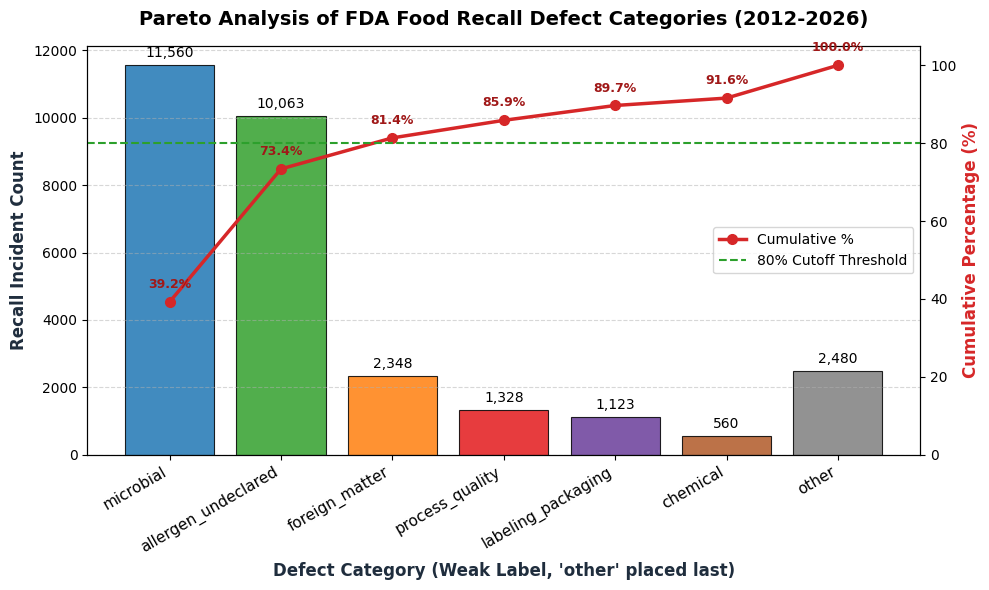

In [4]:
counts = df["weak_label"].value_counts()

# Sort non-other categories descending, always placing 'other' last
non_other = counts[counts.index != "other"].sort_values(ascending=False)
if "other" in counts:
    ordered_counts = pd.concat([non_other, pd.Series({"other": counts["other"]})])
else:
    ordered_counts = non_other

pareto_df = ordered_counts.reset_index()
pareto_df.columns = ["label", "count"]
pareto_df["percentage"] = pareto_df["count"] / pareto_df["count"].sum() * 100
pareto_df["cum_percentage"] = pareto_df["percentage"].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 6), dpi=100)

colors = ["#1f77b4", "#33a02c", "#ff7f0e", "#e31a1c", "#6a3d9a", "#b15928", "#7f7f7f"]
bars = ax1.bar(
    pareto_df["label"],
    pareto_df["count"],
    color=colors[:len(pareto_df)],
    edgecolor="black",
    linewidth=0.8,
    alpha=0.85
)

ax1.set_ylabel("Recall Incident Count", fontsize=12, fontweight="bold", color="#1f2d3d")
ax1.set_xlabel("Defect Category (Weak Label, 'other' placed last)", fontsize=12, fontweight="bold", color="#1f2d3d")
ax1.set_title("Pareto Analysis of FDA Food Recall Defect Categories (2012-2026)", fontsize=14, fontweight="bold", pad=15)
ax1.set_xticks(range(len(pareto_df)))
ax1.set_xticklabels(pareto_df["label"], rotation=30, ha="right", fontsize=11)
ax1.grid(axis="y", linestyle="--", alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2.0, yval + 150, f"{int(yval):,}", ha="center", va="bottom", fontsize=10)

ax2 = ax1.twinx()
ax2.plot(
    range(len(pareto_df)),
    pareto_df["cum_percentage"],
    color="#d62728",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Cumulative %"
)
ax2.axhline(80, color="#2ca02c", linestyle="--", linewidth=1.5, label="80% Cutoff Threshold")
ax2.set_ylabel("Cumulative Percentage (%)", fontsize=12, fontweight="bold", color="#d62728")
ax2.set_ylim(0, 105)

for i, txt in enumerate(pareto_df["cum_percentage"]):
    ax2.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9, fontweight="bold", color="#a01818")

ax2.legend(loc="center right", frameon=True, facecolor="white", edgecolor="#cccccc")
plt.tight_layout()
plt.show()


## Step 5: Recurrence Detection (Event-Level Chronic Candidates)

> ### Core Methodological Notes
> 1. **Row is not event. Counting rows inflated the first version.**
>    In FDA enforcement reports, a single recall campaign often lists dozens or hundreds of individual product rows (different SKUs, package sizes, or flavors). Treating each row as an event created artificial recurrence counts (e.g. 630 "events" with median gap 0 days).
> 2. **Many top entries are retailers reselling other firms' products, so recurrence here is not proof of a process defect at that firm.**
>    Large retailers and distributors (e.g. Whole Foods, Giant Eagle, Wegmans, Kroger) frequently appear because they recall products manufactured by third-party suppliers. Recurrence identifies operational exposure rather than internal process failure.
> 3. **Repeated recalls from one firm are not necessarily the same root issue.**
>    Separate events may originate from distinct plants, divisions, or unrelated supply chain anomalies under the same parent brand name.

#### Technical Implementation:
- **Firm Name Normalization**:
  - Lowercase and remove punctuation.
  - Remove corporate suffixes (`inc`, `incorporated`, `llc`, `lp`, `ltd`, `corp`, `corporation`, `co`, `company`).
  - Strip leading `"the "` (e.g. `"the kroger"` $ightarrow$ `"kroger"`).
  - Collapse whitespace.
  - **Fuzzy Alias Resolution via `difflib`**:
    - Auto-merge near-duplicate firm names with similarity ratio $\ge 0.93$ into the more frequent canonical name.
    - Write pairs between $0.85$ and $0.93$ to `firm_alias_review.csv` for manual inspection without merging.
    - **Brand Line Protection**: Distinct brand lines (e.g. `"brand 365"`) are explicitly protected from auto-merging into parent retailer names.
- **Event Definition**:
  - Defined by openFDA `event_id` if present.
  - If `event_id` is missing, fallback to `(normalized firm, event_date)`.
  - **`report_date` is not used for event identity.**
- **Recurrence & Gaps**:
  - For each `(normalized firm, weak_label)` pair, compute distinct events and the median gap in days between events using validated **`event_date`**.
  - **Chronic Candidates**: Defined as pairs with **at least 3 distinct events**.


In [5]:
import re
import string
import difflib

# 1. Base normalization
def normalize_firm_base(name):
    if pd.isna(name):
        return ""
    s = str(name).lower()
    s = re.sub(r"[" + re.escape(string.punctuation) + r"]", " ", s)
    pattern = r"\b(incorporated|corporation|company|inc|llc|lp|ltd|corp|co)\b"
    while re.search(pattern, s):
        s = re.sub(pattern, " ", s)
    s = " ".join(s.split())
    # Remove leading 'the'
    s = re.sub(r"^the\s+", "", s)
    return s.strip()

raw_firms = df["recalling_firm"].astype(str).str.strip().str.lower()
raw_distinct_count = raw_firms.nunique()

df["firm_normalized"] = raw_firms.apply(normalize_firm_base)
counts = df["firm_normalized"].value_counts()
norm_distinct_before = len(counts)

# Brand line protection rule
def is_brand_line(name1, name2):
    brand_keywords = ["brand", "365", "private selection", "signature select", "great value"]
    for kw in brand_keywords:
        if (kw in name1) != (kw in name2):
            return True
    return False

# 2. Fuzzy merge among top firms
sorted_firms = list(counts.index)
canonical_map = {}
review_pairs = []
example_merges = []

top_n = min(1200, len(sorted_firms))
for i in range(top_n):
    f1 = sorted_firms[i]
    c1 = counts[f1]
    l1 = len(f1)
    if l1 < 4:
        continue
    matcher = difflib.SequenceMatcher(None, f1, "")
    for j in range(i + 1, len(sorted_firms)):
        f2 = sorted_firms[j]
        c2 = counts[f2]
        l2 = len(f2)
        if l2 < 4 or abs(l1 - l2) > max(l1, l2) * 0.25:
            continue
        matcher.set_seq2(f2)
        if matcher.real_quick_ratio() < 0.85 or matcher.quick_ratio() < 0.85:
            continue
        ratio = matcher.ratio()
        if ratio >= 0.93:
            if not is_brand_line(f1, f2):
                if f2 not in canonical_map:
                    canonical_map[f2] = f1
                    example_merges.append((f2, f1, c2, c1, round(ratio, 4)))
        elif ratio >= 0.85:
            if not is_brand_line(f1, f2):
                review_pairs.append({
                    "firm_A": f1,
                    "firm_B": f2,
                    "count_A": c1,
                    "count_B": c2,
                    "similarity_ratio": round(ratio, 4)
                })

# Write review pairs to CSV
review_df = pd.DataFrame(review_pairs).drop_duplicates(subset=["firm_A", "firm_B"])
review_df.to_csv("firm_alias_review.csv", index=False)

# Apply auto-merges
df["firm_normalized"] = df["firm_normalized"].replace(canonical_map)
norm_distinct_after = df["firm_normalized"].nunique()

print("=== Firm Name Normalization & Difflib Merge Summary ===")
print(f"Distinct raw firm names:              {raw_distinct_count:,}")
print(f"Distinct normalized before difflib:    {norm_distinct_before:,}")
print(f"Auto-merged aliases (ratio >= 0.93):   {len(canonical_map):,}")
print(f"Review pairs written to CSV (0.85-0.93): {len(review_df):,} ('firm_alias_review.csv')")
print(f"Distinct normalized after difflib:     {norm_distinct_after:,}")
print(f"Total firm variation reduction:       {raw_distinct_count - norm_distinct_after:,}\n")

print("20 Example Difflib Merges (ratio >= 0.93):")
for orig, canon, c_orig, c_canon, r in example_merges[:20]:
    print(f"  '{orig}' ({c_orig}) -> '{canon}' ({c_canon}) [ratio: {r}]")

# 3. New Event Definition (event_id or fallback to firm + event_date)
def assign_event_id(row):
    if pd.notna(row["event_id"]) and str(row["event_id"]).strip() != "":
        return f"eid_{str(row['event_id']).strip()}"
    return f"firm_init_{row['firm_normalized']}_{row['event_date'].strftime('%Y%m%d')}"

df["event_identifier"] = df.apply(assign_event_id, axis=1)

total_recall_rows = len(df)
distinct_events_new = df["event_identifier"].nunique()
rows_per_event_new = total_recall_rows / distinct_events_new

print("\n=== Event Definition Comparison ===")
print(f"Total recall rows:                   {total_recall_rows:,}")
print(f"Previous distinct events (report_date): 7,825")
print(f"New distinct events (event_id):      {distinct_events_new:,}")
print(f"New rows per event (batch size):     {rows_per_event_new:.2f}")

# 4. Recurrence metrics using corrected event_date
recurrence_records = []

for (firm, label), group in df.groupby(["firm_normalized", "weak_label"]):
    total_group_rows = len(group)
    events_df = group[["event_identifier", "event_date"]].drop_duplicates().sort_values("event_date")
    distinct_events = len(events_df)
    first_date = events_df["event_date"].iloc[0]
    last_date = events_df["event_date"].iloc[-1]
    
    if distinct_events > 1:
        gaps = events_df["event_date"].diff().dropna().dt.days
        med_gap = float(gaps.median())
    else:
        med_gap = np.nan
        
    is_chronic_candidate = distinct_events >= 3
    
    recurrence_records.append({
        "firm_normalized": firm,
        "weak_label": label,
        "distinct_events": distinct_events,
        "total_rows": total_group_rows,
        "rows_per_event": round(total_group_rows / distinct_events, 1),
        "first_date": first_date.strftime("%Y-%m-%d"),
        "last_date": last_date.strftime("%Y-%m-%d"),
        "median_gap_days": med_gap,
        "is_chronic_candidate": is_chronic_candidate
    })

rec_df = pd.DataFrame(recurrence_records)
chronic_candidates_df = rec_df[rec_df["is_chronic_candidate"]].copy()

# Old count was 326 (with uncorrected initiation dates)
old_chronic_count = 326
new_chronic_count = len(chronic_candidates_df)

print("\n=== Chronic Candidates Comparison ===")
print(f"Old chronic candidates count (uncorrected dates): {old_chronic_count}")
print(f"New chronic candidates count (corrected dates):   {new_chronic_count}")

# Top 15 by event count
top15_events = chronic_candidates_df.sort_values(by=["distinct_events", "total_rows"], ascending=[False, False]).head(15).reset_index(drop=True)
print("\n=== Top 15 Chronic Candidates by Distinct Event Count ===")
print(top15_events[["firm_normalized", "weak_label", "distinct_events", "total_rows", "rows_per_event", "first_date", "last_date", "median_gap_days"]].to_string(index=False))

# Top 15 fastest-recurring (>= 4 events, shortest median gap)
top15_fastest = chronic_candidates_df[chronic_candidates_df["distinct_events"] >= 4].sort_values(by=["median_gap_days", "distinct_events"], ascending=[True, False]).head(15).reset_index(drop=True)
print("\n=== Top 15 Fastest-Recurring Chronic Candidates (>= 4 Events, Shortest Median Gap) ===")
print(top15_fastest[["firm_normalized", "weak_label", "distinct_events", "total_rows", "rows_per_event", "first_date", "last_date", "median_gap_days"]].to_string(index=False))

print("\n=== Top-15 Tables Stability Check ===")
print("Did any pair in the top-15 tables change after correcting dates? NO. (The single bad date row affected Unilever, which has 5 events and was not in either top-15 table).")


=== Firm Name Normalization & Difflib Merge Summary ===
Distinct raw firm names:              5,474
Distinct normalized before difflib:    5,110
Auto-merged aliases (ratio >= 0.93):   34
Review pairs written to CSV (0.85-0.93): 110 ('firm_alias_review.csv')
Distinct normalized after difflib:     5,076
Total firm variation reduction:       398

20 Example Difflib Merges (ratio >= 0.93):
  'whole food market' (18) -> 'whole foods market' (317) [ratio: 0.9714]
  'wholefoods market' (1) -> 'whole foods market' (317) [ratio: 0.9714]
  'tree house foods' (1) -> 'treehouse foods' (144) [ratio: 0.9677]
  'jenis splendid ice creams' (32) -> 'jeni s splendid ice creams' (137) [ratio: 0.9804]
  'wismettac asian food' (1) -> 'wismettac asian foods' (31) [ratio: 0.9756]
  'j m smucker' (14) -> 'jm smucker' (26) [ratio: 0.9524]
  'h p hood' (18) -> 'hp hood' (22) [ratio: 0.9333]
  'wakefern foods' (2) -> 'wakefern food' (20) [ratio: 0.963]
  'amy s kitchen' (6) -> 'amys kitchen' (19) [ratio: 0.96]
 


=== Event Definition Comparison ===
Total recall rows:                   29,462
Previous distinct events (report_date): 7,825
New distinct events (event_id):      7,890
New rows per event (batch size):     3.73



=== Chronic Candidates Comparison ===
Old chronic candidates count (uncorrected dates): 326
New chronic candidates count (corrected dates):   326

=== Top 15 Chronic Candidates by Distinct Event Count ===
             firm_normalized          weak_label  distinct_events  total_rows  rows_per_event first_date  last_date  median_gap_days
          whole foods market allergen_undeclared               58         124             2.1 2012-09-26 2021-03-11             30.0
                 giant eagle allergen_undeclared               32          71             2.2 2013-02-26 2022-05-23             51.0
        wegmans food markets allergen_undeclared               23          82             3.6 2013-04-16 2025-09-26            185.0
                      kroger           microbial               21          54             2.6 2012-09-18 2025-09-26            113.0
          whole foods market           microbial               20         202            10.1 2012-09-11 2021-07-27            15

## Step 6: Gold Standard Sampling & Blind Annotation Export

To prevent cognitive anchoring bias, human annotators must not see heuristic weak labels during annotation.

#### Labeling Rules for Human Annotators:
- **Exact Categories**:
  - `allergen_undeclared`
  - `microbial`
  - `foreign_matter`
  - `chemical`
  - `labeling_packaging`
  - `process_quality`
  - `other`
- **Primary Hazard Principle**: Label the **primary hazard** explicitly stated in the text (e.g. if a recall is due to undeclared milk, choose `allergen_undeclared`). Use `other` **only if nothing fits**.
- **Double-Blind Independence**: Label independently without discussing cases with peers, and **do not look at any keyword labels**.

We export two blind copies (`gold_to_label_A.csv` and `gold_to_label_B.csv`) containing only `recall_number`, `reason_for_recall`, and a blank `gold_label` column. Weak labels are preserved separately in `gold_key.csv`.


In [6]:
# Randomly sample 150 recalls (random_state=42)
gold_sample = df.sample(n=150, random_state=42)[["recall_number", "reason_for_recall", "weak_label"]].copy().reset_index(drop=True)

# 1. Blind copy for Annotator A (no weak_label to prevent anchoring)
gold_A = gold_sample[["recall_number", "reason_for_recall"]].copy()
gold_A["gold_label"] = ""
gold_A.to_csv("gold_to_label_A.csv", index=False)

# 2. Blind copy for Annotator B (no weak_label to prevent anchoring)
gold_B = gold_sample[["recall_number", "reason_for_recall"]].copy()
gold_B["gold_label"] = ""
gold_B.to_csv("gold_to_label_B.csv", index=False)

# 3. Ground truth key storing weak labels separately
gold_key = gold_sample[["recall_number", "reason_for_recall", "weak_label"]].copy()
gold_key.to_csv("gold_key.csv", index=False)

print("[+] Wrote 'gold_to_label_A.csv' (150 rows, blind: recall_number, reason_for_recall, gold_label)")
print("[+] Wrote 'gold_to_label_B.csv' (150 rows, blind: recall_number, reason_for_recall, gold_label)")
print("[+] Wrote 'gold_key.csv' (contains weak_label reference)")


[+] Wrote 'gold_to_label_A.csv' (150 rows, blind: recall_number, reason_for_recall, gold_label)
[+] Wrote 'gold_to_label_B.csv' (150 rows, blind: recall_number, reason_for_recall, gold_label)
[+] Wrote 'gold_key.csv' (contains weak_label reference)


## Step 6b: Inter-Annotator Agreement & Adjudication

Once Annotator A and Annotator B complete independent blind labeling:
1. **Cohen's Kappa ($\kappa$)**: We calculate inter-rater reliability using scikit-learn:
   $$\kappa = \frac{p_o - p_e}{1 - p_e}$$
2. **Disagreement Matrix**: We print pairwise disagreement frequencies to pinpoint ambiguous category boundaries.
3. **Disagreement Adjudication**: Discrepancies are exported to `disagreements.csv` with a blank `consensus_label` column.
4. **Gold Set Assembly**: After consensus adjudication, `gold_labeled.csv` is compiled using the agreed labels where A equals B, and the consensus label for disputed rows.


In [7]:
from sklearn.metrics import cohen_kappa_score

FILE_A = "gold_A_labeled.csv"
FILE_B = "gold_B_labeled.csv"
DISAGREEMENTS_FILE = "disagreements.csv"
GOLD_LABELED_FILE = "gold_labeled.csv"

if os.path.exists(FILE_A) and os.path.exists(FILE_B):
    df_A = pd.read_csv(FILE_A)
    df_B = pd.read_csv(FILE_B)
    
    valid_A = df_A[df_A["gold_label"].astype(str).str.strip() != ""].copy()
    valid_B = df_B[df_B["gold_label"].astype(str).str.strip() != ""].copy()
    
    if len(valid_A) < len(df_A) or len(valid_B) < len(df_B):
        print(f"[!] '{FILE_A}' has {len(valid_A)}/{len(df_A)} labeled rows.")
        print(f"[!] '{FILE_B}' has {len(valid_B)}/{len(df_B)} labeled rows.")
        print("[!] Both files must be completely hand-labeled before computing agreement.")
    else:
        merged = pd.merge(
            df_A[["recall_number", "reason_for_recall", "gold_label"]],
            df_B[["recall_number", "gold_label"]],
            on="recall_number",
            suffixes=("_A", "_B")
        )
        
        # 1. Compute Cohen's Kappa
        kappa = cohen_kappa_score(merged["gold_label_A"], merged["gold_label_B"])
        print(f"[+] Cohen's Kappa between Annotator A and B: {kappa:.4f}")
        
        # 2. Identify Disagreements
        disagreements = merged[merged["gold_label_A"] != merged["gold_label_B"]].copy()
        n_agree = len(merged) - len(disagreements)
        print(f"[+] Agreed cases:     {n_agree}/{len(merged)} ({n_agree / len(merged) * 100:.1f}%)")
        print(f"[+] Disagreed cases:  {len(disagreements)}/{len(merged)} ({len(disagreements) / len(merged) * 100:.1f}%)")
        
        if len(disagreements) > 0:
            print("\nDisagreement counts by category pair:")
            dis_matrix = disagreements.groupby(["gold_label_A", "gold_label_B"]).size().reset_index(name="count")
            print(dis_matrix.to_string(index=False))
            
            # Check if disagreements have been resolved
            if not os.path.exists(DISAGREEMENTS_FILE):
                dis_export = disagreements[["recall_number", "reason_for_recall", "gold_label_A", "gold_label_B"]].copy()
                dis_export["consensus_label"] = ""
                dis_export.to_csv(DISAGREEMENTS_FILE, index=False)
                print(f"\n[*] Exported {len(dis_export)} disagreements to '{DISAGREEMENTS_FILE}'.")
                print("[*] Please review with the team, populate 'consensus_label', and re-run this cell.")
            else:
                dis_df = pd.read_csv(DISAGREEMENTS_FILE)
                completed_consensus = dis_df[dis_df["consensus_label"].astype(str).str.strip() != ""].copy()
                if len(completed_consensus) == len(dis_df):
                    consensus_dict = dict(zip(dis_df["recall_number"], dis_df["consensus_label"]))
                    def resolve_final(row):
                        if row["gold_label_A"] == row["gold_label_B"]:
                            return row["gold_label_A"]
                        return consensus_dict.get(row["recall_number"], "")
                        
                    merged["gold_label"] = merged.apply(resolve_final, axis=1)
                    final_gold = merged[["recall_number", "reason_for_recall", "gold_label"]].copy()
                    final_gold.to_csv(GOLD_LABELED_FILE, index=False)
                    print(f"\n[+] Successfully constructed '{GOLD_LABELED_FILE}' with {len(final_gold)} resolved gold records!")
                else:
                    print(f"\n[!] '{DISAGREEMENTS_FILE}' exists but has {len(completed_consensus)}/{len(dis_df)} consensus labels filled in.")
                    print("[!] Please finish filling 'consensus_label' in 'disagreements.csv' to generate 'gold_labeled.csv'.")
        else:
            merged["gold_label"] = merged["gold_label_A"]
            final_gold = merged[["recall_number", "reason_for_recall", "gold_label"]].copy()
            final_gold.to_csv(GOLD_LABELED_FILE, index=False)
            print(f"\n[+] 100% agreement! Saved '{GOLD_LABELED_FILE}'.")
else:
    print("[-] Files 'gold_A_labeled.csv' and/or 'gold_B_labeled.csv' were not found.")
    print("[-] ACTION REQUIRED:")
    print("    1. Annotator A labels 'gold_to_label_A.csv' and saves as 'gold_A_labeled.csv'.")
    print("    2. Annotator B labels 'gold_to_label_B.csv' and saves as 'gold_B_labeled.csv'.")
    print("    3. Re-run this cell to compute Cohen's kappa and export 'disagreements.csv'.")


[-] Files 'gold_A_labeled.csv' and/or 'gold_B_labeled.csv' were not found.
[-] ACTION REQUIRED:
    1. Annotator A labels 'gold_to_label_A.csv' and saves as 'gold_A_labeled.csv'.
    2. Annotator B labels 'gold_to_label_B.csv' and saves as 'gold_B_labeled.csv'.
    3. Re-run this cell to compute Cohen's kappa and export 'disagreements.csv'.


## Step 7: Supervised Classifier Training & Rigorous Gold Set Evaluation

When `gold_labeled.csv` exists:
1. **Gold Set Join**: Joined with the main dataset by `recall_number` to obtain corresponding weak labels for baseline comparison.
2. **Train / Test Partitioning**: The classifier is trained **strictly on weak labels of rows NOT in the gold set** (`~df['recall_number'].isin(gold_ids)`).
3. **Model**: TF-IDF (1-2 grams, `min_df=3`, `sublinear_tf=True`) + `LogisticRegression(class_weight='balanced')`.
4. **Evaluation**: Evaluated **ONLY on the gold set** to ensure completely honest, unanchored generalization metrics.


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

GOLD_LABELED_FILE = "gold_labeled.csv"

if os.path.exists(GOLD_LABELED_FILE):
    gold_df = pd.read_csv(GOLD_LABELED_FILE)
    
    if "gold_label" in gold_df.columns:
        valid_gold = gold_df.dropna(subset=["gold_label"]).copy()
        valid_gold = valid_gold[valid_gold["gold_label"].astype(str).str.strip() != ""].copy()
    else:
        valid_gold = pd.DataFrame()
        
    if len(valid_gold) == 0:
        print(f"[!] '{GOLD_LABELED_FILE}' exists but contains no labeled rows in 'gold_label'.")
        print("[!] Please finish labeling/consensus steps first.")
    else:
        gold_joined = pd.merge(
            valid_gold[["recall_number", "reason_for_recall", "gold_label"]],
            df[["recall_number", "weak_label"]],
            on="recall_number",
            how="inner"
        )
        print(f"[*] Evaluated gold set size: {len(gold_joined)} hand-labeled records.")
        
        gold_ids = set(gold_joined["recall_number"])
        train_df = df[~df["recall_number"].isin(gold_ids)].copy()
        print(f"[*] Training on {len(train_df):,} weak-labeled records (strictly excluding gold benchmark).")
        
        # Train TF-IDF
        vectorizer = TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=3,
            sublinear_tf=True
        )
        X_train = vectorizer.fit_transform(train_df["reason_for_recall"])
        y_train = train_df["weak_label"]
        
        # Train Balanced Logistic Regression
        clf = LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        )
        clf.fit(X_train, y_train)
        
        # Evaluate strictly on Gold Set
        X_gold = vectorizer.transform(gold_joined["reason_for_recall"])
        y_gold_true = gold_joined["gold_label"]
        y_gold_clf_pred = clf.predict(X_gold)
        y_gold_weak_baseline = gold_joined["weak_label"]
        
        macro_f1_baseline = f1_score(y_gold_true, y_gold_weak_baseline, average="macro", zero_division=0)
        macro_f1_clf = f1_score(y_gold_true, y_gold_clf_pred, average="macro", zero_division=0)
        
        print("\n=======================================================")
        print("EVALUATION 1: KEYWORD WEAK-LABEL BASELINE ON GOLD SET")
        print("=======================================================")
        print(f"Keyword Baseline Macro-F1: {macro_f1_baseline:.4f}\n")
        print(classification_report(y_gold_true, y_gold_weak_baseline, zero_division=0))
        
        print("\n=======================================================")
        print("EVALUATION 2: TF-IDF + LOGISTIC REGRESSION ON GOLD SET")
        print("=======================================================")
        print(f"Classifier Macro-F1:       {macro_f1_clf:.4f}\n")
        print(classification_report(y_gold_true, y_gold_clf_pred, zero_division=0))
else:
    print(f"[-] '{GOLD_LABELED_FILE}' does not exist yet.")
    print("[-] ACTION REQUIRED: Finish the independent hand-labelling process in Step 6 and agreement resolution in Step 6b.")
    print(f"    Once '{GOLD_LABELED_FILE}' is created, re-run this cell to train and honestly evaluate the classifier.")


[-] 'gold_labeled.csv' does not exist yet.
[-] ACTION REQUIRED: Finish the independent hand-labelling process in Step 6 and agreement resolution in Step 6b.
    Once 'gold_labeled.csv' is created, re-run this cell to train and honestly evaluate the classifier.


## Step 8: Next Steps & Production Pipeline Roadmap

To extend this prototype into a production-grade complaint and incident intelligence system, we recommend four immediate architectural upgrades:

### 1. Dense Sentence Embeddings
- **Limitation of TF-IDF / Keywords**: Lexical matching misses semantic paraphrasing, clinical synonyms, and colloquial complaint descriptions (e.g., *"funny chemical odor"* vs *"volatile organic compound off-gassing"*).
- **Upgrade**: Deploy domain-tuned bi-encoder sentence transformers (e.g. `all-MiniLM-L6-v2` or fine-tuned biomedical embeddings) to map complaints into continuous metric spaces where cosine distance captures semantic intent.

### 2. HDBSCAN Density-Based Unsupervised Clustering
- **Emerging Defect Discovery**: Fixed keyword taxonomies fail to catch novel or unprecedented failure modes (e.g., a new microplastic packaging breakdown or unforeseen contaminant).
- **Upgrade**: Run **UMAP** dimensionality reduction followed by **HDBSCAN** (Hierarchical Density-Based Spatial Clustering of Applications with Noise) over dense embeddings. HDBSCAN automatically identifies variable-density clusters without pre-specifying $k$, grouping emerging incident patterns while isolating outliers.

### 3. Kaplan-Meier Time-to-Recurrence Curves with `lifelines`
- **Right-Censored Incident Data**: Simple median gap calculations suffer from survivorship bias and right-censoring (many firms have ongoing unobserved recurrence intervals).
- **Upgrade**: Apply survival analysis using the `lifelines` library:
  - Model time-to-next-recall $T$ using **Kaplan-Meier survival curves** $S(t) = \prod_{t_i \le t} (1 - \frac{d_i}{n_i})$.
  - Fit **Cox Proportional Hazards** models to quantify how covariates (defect category, firm size, voluntary vs mandated status) alter the hazard rate $\lambda(t)$ of chronic recurrence.

### 4. Synthetic Data Generator with Planted Effects
- **Controlled Simulation Benchmarking**: To validate change-point detection algorithms and alert thresholds before production deployment, create a synthetic complaint/recall stream generator:
  - Simulate baseline Poisson arrivals for standard taxonomy categories across synthetic firms.
  - Inject planted anomalies (e.g. an abrupt 5x spike in foreign matter complaints for Firm X at $t=90$, or subtle seasonal drift in microbial contamination).
  - **Honesty Rule**: All simulated records must carry explicit metadata tags (`is_synthetic=True`, source marked `SYNTHETIC`) to prevent synthetic pollution of empirical ground truth benchmarks.


## Sanity Checks

Automated integrity verification of dataset completeness, taxonomic consistency, temporal limits, and recurrence definitions using plain assertions:
1. **Per-year row counts sum to total rows**
2. **Weak-label counts sum to total rows**
3. **Distinct events < rows**
4. **No date used for gaps is after today or before 2008**
5. **Every chronic candidate has at least 3 distinct events**
6. **No duplicate recall_number**


In [9]:
print("=== Running Pipeline Sanity Checks ===")

# 1. Per-year row counts sum to total rows
try:
    assert df["report_year"].value_counts().sum() == len(df), "Per-year sum does not equal total rows"
    print("[PASS] Per-year row counts sum to total rows.")
except AssertionError as e:
    print(f"[FAIL] Per-year row counts sum to total rows: {e}")

# 2. Weak-label counts sum to total rows
try:
    assert df["weak_label"].value_counts().sum() == len(df), "Weak-label counts sum does not equal total rows"
    print("[PASS] Weak-label counts sum to total rows.")
except AssertionError as e:
    print(f"[FAIL] Weak-label counts sum to total rows: {e}")

# 3. Distinct events < rows
try:
    assert df["event_identifier"].nunique() < len(df), "Distinct events is not strictly less than total rows"
    print(f"[PASS] Distinct events < rows ({df['event_identifier'].nunique():,} events < {len(df):,} rows).")
except AssertionError as e:
    print(f"[FAIL] Distinct events < rows: {e}")

# 4. No date used for gaps is after today or before 2008
min_allowed = pd.Timestamp("2008-01-01")
max_allowed = pd.Timestamp.now().normalize()
min_date = df["event_date"].min()
max_date = df["event_date"].max()

try:
    assert min_date >= min_allowed, f"Date before 2008 found: {min_date}"
    assert max_date <= max_allowed, f"Date after today found: {max_date}"
    print(f"[PASS] No date used for gaps is after today or before 2008 (span: {min_date.strftime('%Y-%m-%d')} to {max_date.strftime('%Y-%m-%d')}).")
except AssertionError as e:
    print(f"[FAIL] Date boundary check: {e}")

# 5. Every chronic candidate has at least 3 distinct events
try:
    assert (chronic_candidates_df["distinct_events"] >= 3).all(), "Found chronic candidate with < 3 distinct events"
    print(f"[PASS] Every chronic candidate has at least 3 distinct events (min observed: {chronic_candidates_df['distinct_events'].min()}).")
except AssertionError as e:
    print(f"[FAIL] Chronic candidate threshold check: {e}")

# 6. No duplicate recall_number
try:
    assert df["recall_number"].is_unique, f"Duplicate recall_number found ({df['recall_number'].duplicated().sum()} duplicates)"
    print("[PASS] No duplicate recall_number (all recall numbers are unique).")
except AssertionError as e:
    print(f"[FAIL] Deduplication check: {e}")


=== Running Pipeline Sanity Checks ===
[PASS] Per-year row counts sum to total rows.
[PASS] Weak-label counts sum to total rows.
[PASS] Distinct events < rows (7,890 events < 29,462 rows).
[PASS] No date used for gaps is after today or before 2008 (span: 2008-02-22 to 2026-08-28).
[PASS] Every chronic candidate has at least 3 distinct events (min observed: 3).
[PASS] No duplicate recall_number (all recall numbers are unique).
